# PCE Model for Depth-Based CPT Prediction (Multi-Output)


In [1]:
from __future__ import annotations

import importlib
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from uqpylab import sessions
from numpy.polynomial.legendre import legval
import math

# Import utility functions from modules
from pce_utils import calculate_r2
import utils 
from scipy import stats
import pandas as pd
import seaborn as sns
import matplotlib.ticker as ticker

import json
from scipy.interpolate import RBFInterpolator

from config import UQCLOUD_TOKEN
myToken = UQCLOUD_TOKEN

# Reload utils module to pick up any changes
importlib.reload(utils)
from utils import (
    nrmsd,
    set_graphics_defaults,
)
from pandas.plotting import scatter_matrix

# Notebook-compatible path resolution
if Path.cwd().name == "src":
    ROOT = Path.cwd().parent
else:
    ROOT = Path.cwd()

DATA_DIR = ROOT / "data"
PLOTS_DIR = ROOT / "graphics"
PLOTS_DIR.mkdir(exist_ok=True)
cm = 1/2.54

In [2]:
# Start UQ[PY]LAB session
UQCloud_instance = os.environ.get("UQCLOUD_HOST", "https://uqcloud.ethz.ch")
myToken = os.environ.get("UQCLOUD_TOKEN", f"{myToken}")

mySession = sessions.cloud(host=UQCloud_instance, token=myToken, strict_ssl=True)
uq = mySession.cli
mySession.reset()

print("UQ[PY]LAB session started.")

Processing .. done!

 uqpylab.sessions :: INFO     :: This is UQ[py]Lab, version 1.0, running on https://uqcloud.ethz.ch. 
                                 UQ[py]Lab is free software, published under the open source BSD 3-clause license.
                                 To request special permissions, please contact:
                                  - Stefano Marelli (marelli@ibk.baug.ethz.ch).
                                 A new session (682498b277f74e7fb20999e0b249fe1a) started.
 uqpylab.sessions :: INFO     :: Reset successful.
UQ[PY]LAB session started.


In [3]:
data_dir = Path(DATA_DIR / "02_database")
file_name = "inverse_training_consistency_4000.csv"
file_path = data_dir / file_name

PCE_database_total = pd.read_csv(file_path)

array([[<Axes: xlabel='gamma', ylabel='gamma'>,
        <Axes: xlabel='phi', ylabel='gamma'>,
        <Axes: xlabel='ocr', ylabel='gamma'>,
        <Axes: xlabel='cr', ylabel='gamma'>,
        <Axes: xlabel='cs_cc', ylabel='gamma'>,
        <Axes: xlabel='depth', ylabel='gamma'>,
        <Axes: xlabel='qt', ylabel='gamma'>,
        <Axes: xlabel='fs', ylabel='gamma'>,
        <Axes: xlabel='u2', ylabel='gamma'>],
       [<Axes: xlabel='gamma', ylabel='phi'>,
        <Axes: xlabel='phi', ylabel='phi'>,
        <Axes: xlabel='ocr', ylabel='phi'>,
        <Axes: xlabel='cr', ylabel='phi'>,
        <Axes: xlabel='cs_cc', ylabel='phi'>,
        <Axes: xlabel='depth', ylabel='phi'>,
        <Axes: xlabel='qt', ylabel='phi'>,
        <Axes: xlabel='fs', ylabel='phi'>,
        <Axes: xlabel='u2', ylabel='phi'>],
       [<Axes: xlabel='gamma', ylabel='ocr'>,
        <Axes: xlabel='phi', ylabel='ocr'>,
        <Axes: xlabel='ocr', ylabel='ocr'>,
        <Axes: xlabel='cr', ylabel='ocr'>,
       

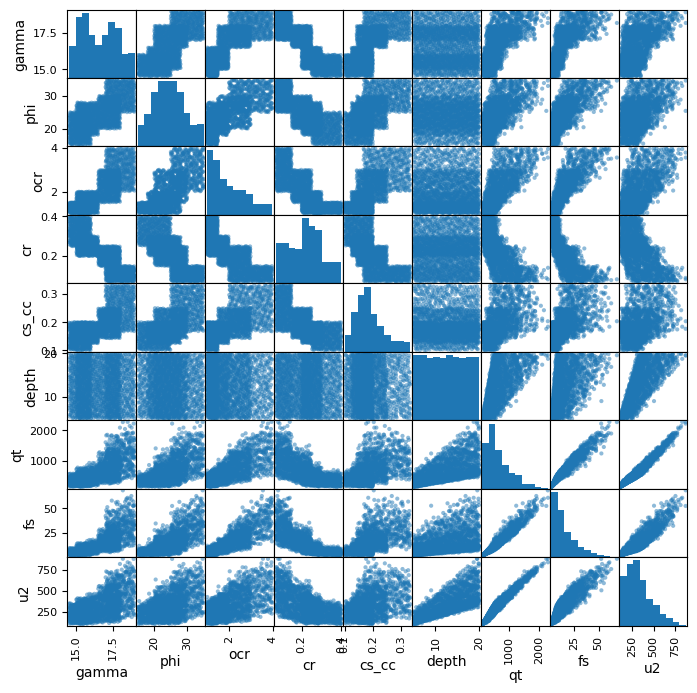

In [4]:
from pandas.plotting import scatter_matrix

scatter_matrix(PCE_database_total, figsize=(8,8))

In [5]:
ed = PCE_database_total[['depth', 'qt', 'fs', 'u2']]
out = PCE_database_total[['gamma', 'phi', 'ocr', 'cr', 'cs_cc']]

output_var_names = ['gamma', 'phi', 'ocr', 'cr', 'cs_cc']

In [6]:
# 1) compute global bounds on Y
bounds = {c: (float(out[c].min()), float(out[c].max())) for c in output_var_names}
print(bounds)

{'gamma': (14.5029296875, 18.99609375), 'phi': (15.01953125, 34.9609375), 'ocr': (1.001953125, 3.99609375), 'cr': (0.07015625, 0.3994140625), 'cs_cc': (0.1001953125, 0.3323515625)}


In [7]:
latex_names = {
"z" : "z (m)",
"gamma": "$\gamma_{sat}$ (kN/m$^3$)",
"phi": "$\\varphi'~(°)$",
"ocr": "OCR (-)",
"cr": "$C_R$ (-)",
"cs_cc": "$C_S/C_C$ (-)",
}

In [8]:
param_names = list(latex_names.keys())
param_names = param_names[1:]
param_names

['gamma', 'phi', 'ocr', 'cr', 'cs_cc']

In [9]:
# Options: 'AIC', 'BIC', 'ML', or 'KS' (Kolmogorov–Smirnov; marginals only)
criterion = 'KS'

iOpts = {
    'Inference': {
        'Data': ed.values.tolist(),
        'Criterion': 'KS', # KS is often better for "visual" matching
    },
    'Copula': {'Type': 'Auto'},
    # Suggest specific types for problematic columns
    'Marginals': [
        {'Type': 'Auto'}, 
        {'Type': 'LogNormal'}, 
        {'Type': 'LogNormal'}, 
        {'Type': 'LogNormal'}, 
    ]
}
my_input = uq.createInput(iOpts)

Processing ..... done!



In [10]:
# Print the inferred distribution types and their parameters
for i, marginal in enumerate(my_input['Marginals']):
    var_name = ed.columns[i]
    dist_type = marginal['Type']
    params = marginal['Parameters']
    print(f"Variable: {var_name}")
    print(f"  - Inferred Distribution: {dist_type}")
    print(f"  - Parameters: {params}\n")

Variable: depth
  - Inferred Distribution: Uniform
  - Parameters: [5.019976806640625, 19.950726318359376]

Variable: qt
  - Inferred Distribution: LogNormal
  - Parameters: [6.366530170873374, 0.5644491716060611]

Variable: fs
  - Inferred Distribution: LogNormal
  - Parameters: [2.486359836710671, 0.728427125511897]

Variable: u2
  - Inferred Distribution: LogNormal
  - Parameters: [5.693961796455333, 0.4534454237981271]



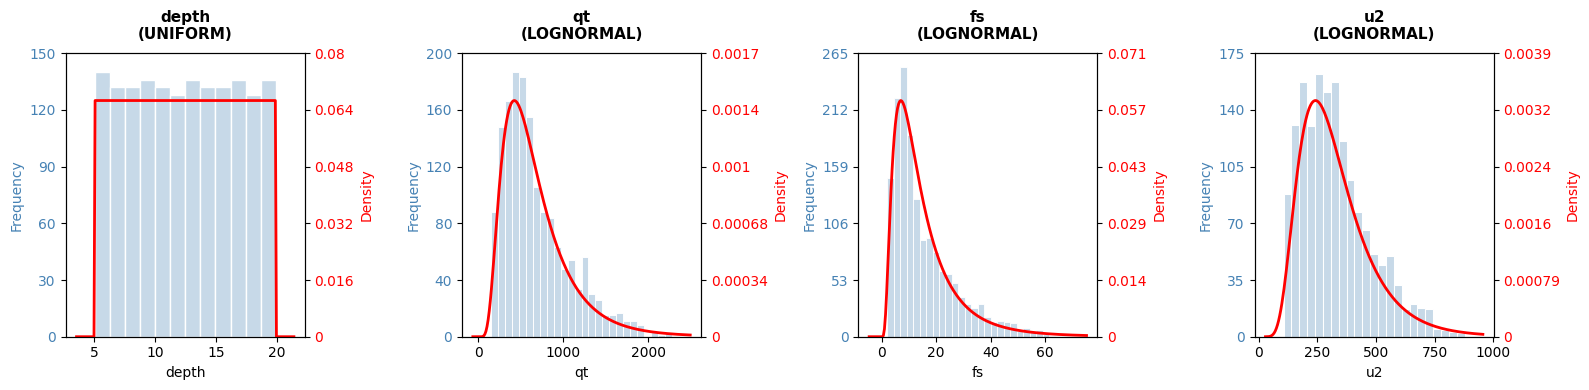

In [11]:
# 1. Setup the figure layout
num_cols = len(ed.columns)
fig, axes = plt.subplots(1, num_cols, figsize=(num_cols * 4, 4))
if num_cols == 1: axes = [axes]

# Set the number of ticks you want for BOTH axes
num_ticks = 6 

for i, col in enumerate(ed.columns):
    ax1 = axes[i]
    
    # --- LEFT AXIS: Frequency ---
    sns.histplot(ed[col], stat='count', alpha=0.3, color='steelblue', edgecolor='white', ax=ax1)
    ax1.set_ylabel('Frequency', color='steelblue', fontsize=10)
    ax1.tick_params(axis='y', labelcolor='steelblue')
    
    # Force alignment for left axis
    ax1.yaxis.set_major_locator(ticker.LinearLocator(num_ticks))
    # Ensure it starts at 0 and ends at a clean integer for counts
    ax1.set_ylim(0, np.ceil(ax1.get_ylim()[1] / 5) * 5 if ax1.get_ylim()[1] > 5 else ax1.get_ylim()[1])

    # --- RIGHT AXIS: Density ---
    ax2 = ax1.twinx() 
    
    marginal = my_input['Marginals'][i]
    dist_type = marginal['Type'].lower()
    params = marginal['Parameters']
    
    x_min, x_max = ed[col].min(), ed[col].max()
    padding = (x_max - x_min) * 0.1
    x_range = np.linspace(x_min - padding, x_max + padding, 200)
    
    y_pdf = None
    if dist_type in ['gaussian', 'normal']:
        y_pdf = stats.norm.pdf(x_range, loc=params[0], scale=params[1])
    elif dist_type == 'lognormal':
        y_pdf = stats.lognorm.pdf(x_range, s=params[1], scale=np.exp(params[0]))
    elif dist_type == 'uniform':
        y_pdf = stats.uniform.pdf(x_range, loc=params[0], scale=params[1]-params[0])
    elif dist_type == 'weibull':
        y_pdf = stats.weibull_min.pdf(x_range, c=params[1], scale=params[0])
    elif dist_type == 'gamma':
            # Check if you have 2 or 3 parameters
            if len(params) == 3:
                y_pdf = stats.gamma.pdf(x_range, a=params[0], loc=params[1], scale=params[2])
            else:
                # If you only have [shape, scale], the distribution assumes it starts at 0.
                # To fix the plot, you likely need to pass the data's minimum as loc:
                loc_guess = x_min 
                y_pdf = stats.gamma.pdf(x_range, a=params[0], loc=loc_guess, scale=params[1])
    elif dist_type == 'beta':
        y_pdf = stats.beta.pdf(x_range, a=params[0], b=params[1])

    if y_pdf is not None:
        ax2.plot(x_range, y_pdf, color='red', lw=2)
        ax2.set_ylabel('Density', color='red', fontsize=10)
        ax2.tick_params(axis='y', labelcolor='red')
        
        # Force alignment for right axis
        ax2.set_ylim(0, max(y_pdf) * 1.2)
        ax2.yaxis.set_major_locator(ticker.LinearLocator(num_ticks))
        ax2.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2g'))
        
    ax1.set_title(f"{col}\n({dist_type.upper()})", fontsize=11, fontweight='bold', pad=10)

plt.tight_layout()

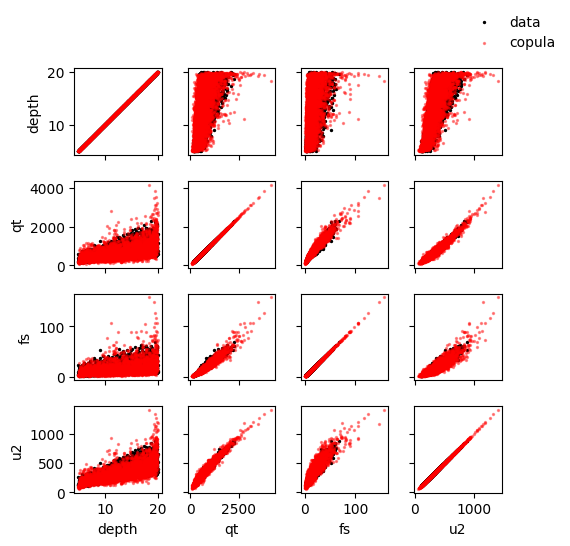

In [12]:
# 1) Sample from the (output) copula
N_COPULA = 4000
Y_copula = np.array(uq.getSample(my_input, N_COPULA, "LHS"))

cm = 1 / 2.54

# Use ed (parameters) as data space for copula check
X = ed.to_numpy(float)   # shape (N, n_params)
n = X.shape[1]           # number of parameters

fig, axes = plt.subplots(
    n, n,
    figsize=(14 * cm, 14 * cm),
    sharex=False,
    sharey=False,
)

for y_idx in range(n):
    for x_idx in range(n):
        ax = axes[y_idx, x_idx]

        y_data = X[:, y_idx]
        x_data = X[:, x_idx]
        y_cop  = Y_copula[:, y_idx]
        x_cop  = Y_copula[:, x_idx]

        # Scatter only (no histograms)
        ax.scatter(x_data, y_data, c="k", s=2, label="data")
        ax.scatter(x_cop, y_cop, c="r", s=2, alpha=0.4, label="copula")

        name_i = ed.columns[y_idx]
        name_j = ed.columns[x_idx]

        if x_idx == 0:
            ax.set_ylabel(name_i)
        else:
            ax.set_yticklabels([])

        if y_idx == n - 1:
            ax.set_xlabel(name_j)
        else:
            ax.set_xticklabels([])

# Legend from first axis
handles, labels = axes[0, 0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc="upper right",
               bbox_to_anchor=(1.02, 1.0), frameon=False)

plt.subplots_adjust(wspace=0.3, hspace=0.3)
plt.show()

In [13]:
X_train, X_test, Y_train, Y_test = train_test_split(
    ed.values, out.values, test_size=0.2, random_state=33
)

print(f"\nTrain/test split (80/20): X_train {X_train.shape}, X_test {X_test.shape}")
print(f"\nTrain/test split (80/20): Y_train {Y_train.shape}, Y_test {Y_test.shape}")


Train/test split (80/20): X_train (1280, 4), X_test (320, 4)

Train/test split (80/20): Y_train (1280, 5), Y_test (320, 5)


In [14]:
# Build multi-output PCE model
print("Building multi-output PCE model...")
print("=" * 60)

# Define configurations to test
configurations = [
    ("LARS", 5, 1e-3),
    ("LARS", 4, 1e-3),
    ("LARS", 10, 1e-3),
    ("LARS", 5, 1e-4),
    ("LARS", 3, 1e-4)
]

best_model = None
best_prediction = None
best_r2 = float('-inf')
best_config = None

print("\nTesting configurations:")
for method, max_degree, target_acc in configurations:
    try:
        meta_opts = {
            "Type": "Metamodel",
            "Input": my_input["Name"],
            "MetaType": "PCE",
            "Degree": list(range(1, max_degree + 1)),
            "Method": method,
            # "TargetAccuracy": target_acc, #not recommended, keep it
            "Display": "quiet",
            "ExpDesign": {
                "X": X_train.tolist(),
                "Y": Y_train.tolist()  
            }
        }
        
        my_pce = uq.createModel(meta_opts)
        prediction_test = uq.evalModel(my_pce, X_test.tolist())

        
        # Calculate average R² on test set
        r2_values = []
        for out_idx, out_name in enumerate(param_names):
            actual = Y_test[:, out_idx]
            predicted = prediction_test[:, out_idx].flatten()
            r2 = calculate_r2(actual, predicted)
            r2_values.append(r2)
    
        avg_r2 = np.mean(r2_values)
        
        config_str = f"Method={method}, MaxDegree={max_degree}, TargetAcc={target_acc}"
        r2_str = ", ".join([f"{n}={v:.6f}" for n, v in zip(param_names, r2_values)])
        print(f"  {config_str}: Avg R² = {avg_r2:.6f} ({r2_str})")
        
        if avg_r2 > best_r2:
            best_r2 = avg_r2
            best_model = my_pce
            best_prediction = prediction_test
            best_config = config_str
            
    except Exception as e:
        print(f"  Method={method}, MaxDegree={max_degree}, TargetAcc={target_acc}: Failed - {str(e)}")
        continue


print(f"\n→ Selected: {best_config} (Avg R² = {best_r2:.6f})")
print("=" * 60)
print("Multi-output PCE model computed successfully.")


# Extract predictions for each output (depth, qt, u2, fs)
prediction_pce = {
    name: best_prediction[:, idx].flatten()
    for idx, name in enumerate(param_names)
}
pce_model = best_model

Building multi-output PCE model...

Testing configurations:
  Method=LARS, MaxDegree=5, TargetAcc=0.001: Avg R² = 0.787323 (gamma=0.862568, phi=0.711373, ocr=0.931959, cr=0.884817, cs_cc=0.545898)
  Method=LARS, MaxDegree=4, TargetAcc=0.001: Avg R² = 0.790487 (gamma=0.862568, phi=0.727195, ocr=0.931959, cr=0.884817, cs_cc=0.545898)
  Method=LARS, MaxDegree=10, TargetAcc=0.001: Avg R² = 0.787323 (gamma=0.862568, phi=0.711373, ocr=0.931959, cr=0.884817, cs_cc=0.545898)
  Method=LARS, MaxDegree=5, TargetAcc=0.0001: Avg R² = 0.787323 (gamma=0.862568, phi=0.711373, ocr=0.931959, cr=0.884817, cs_cc=0.545898)
  Method=LARS, MaxDegree=3, TargetAcc=0.0001: Avg R² = 0.785847 (gamma=0.862568, phi=0.703992, ocr=0.931959, cr=0.884817, cs_cc=0.545898)

→ Selected: Method=LARS, MaxDegree=4, TargetAcc=0.001 (Avg R² = 0.790487)
Multi-output PCE model computed successfully.


In [15]:
# Model Evaluation (on test set)
print("\n" + "=" * 60)
print("MODEL EVALUATION METRICS (Test Set)")
print("=" * 60)

# Inverse PCE: Y_test columns = soil params (same order as param_names)
out_test = {name: Y_test[:, idx] for idx, name in enumerate(param_names)}

# out_test = {col: df_test_phys[col].to_numpy() for col in output_var_names}
evaluation_results = {}

for out_idx, out_name in enumerate(output_var_names):
    actual = out_test[out_name]
    predicted = prediction_pce[out_name]
    
    # Calculate metrics
    r2 = calculate_r2(actual, predicted)
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    mae = np.mean(np.abs(actual - predicted))
    nrmse_range = nrmsd(actual, predicted, norm="range")
    nrmse_std = nrmsd(actual, predicted, norm="std")
    
    # For multi-output PCE, LOO error extraction
    # Note: For multi-output PCE, UQPyLab typically computes LOO error for the first output only
    # We'll try to extract it from the model structure or compute it manually
    loo_rmse = np.nan
    loo_mse = np.nan
    
    # Try to get LOO error from model structure
    try:
        # Check PCE structure directly
        if "PCE" in pce_model:
            pce = pce_model["PCE"]
        else:
            pce = pce_model
        
        # Check for Error structure in PCE
        if "Error" in pce:
            error_obj = pce["Error"]
            if isinstance(error_obj, dict):
                # Check for LOO error (MSE format)
                if "LOO" in error_obj:
                    loo_val = error_obj["LOO"]
                    # For multi-output, LOO might be a list/array per output
                    if isinstance(loo_val, (list, np.ndarray)):
                        loo_array = np.asarray(loo_val).flatten()
                        if len(loo_array) > out_idx:
                            loo_mse = float(loo_array[out_idx])
                            loo_rmse = np.sqrt(loo_mse) if loo_mse > 0 else np.nan
                        elif len(loo_array) == 1 and out_idx == 0:
                            # Single value for first output (common in multi-output)
                            loo_mse = float(loo_array[0])
                            loo_rmse = np.sqrt(loo_mse) if loo_mse > 0 else np.nan
                    elif isinstance(loo_val, (int, float)):
                        # Single scalar value (typically for first output in multi-output)
                        if out_idx == 0:
                            loo_mse = float(loo_val)
                            loo_rmse = np.sqrt(loo_mse) if loo_mse > 0 else np.nan
        
        # Also check top-level Error in model
        if "Error" in pce_model and np.isnan(loo_rmse):
            error_obj = pce_model["Error"]
            if isinstance(error_obj, dict):
                if "LOO" in error_obj:
                    loo_val = error_obj["LOO"]
                    if isinstance(loo_val, (list, np.ndarray)):
                        loo_array = np.asarray(loo_val).flatten()
                        if len(loo_array) > out_idx:
                            loo_mse = float(loo_array[out_idx])
                            loo_rmse = np.sqrt(loo_mse) if loo_mse > 0 else np.nan
                        elif len(loo_array) == 1 and out_idx == 0:
                            loo_mse = float(loo_array[0])
                            loo_rmse = np.sqrt(loo_mse) if loo_mse > 0 else np.nan
                    elif isinstance(loo_val, (int, float)) and out_idx == 0:
                        loo_mse = float(loo_val)
                        loo_rmse = np.sqrt(loo_mse) if loo_mse > 0 else np.nan
        
        # For multi-output models, if LOO is not found per output, 
        # compute it manually using hat matrix approximation
        if np.isnan(loo_rmse):
            try:
                # Manual LOO computation using hat matrix approximation
                n_samples = len(actual)
                residuals = actual - predicted
                
                # Get number of coefficients from PCE model
                if "PCE" in pce_model:
                    pce = pce_model["PCE"]
                else:
                    pce = pce_model
                
                # Estimate number of coefficients
                if "Basis" in pce and "Indices" in pce["Basis"]:
                    n_coeffs = len(pce["Basis"]["Indices"])
                elif "Coefficients" in pce:
                    n_coeffs = len(pce["Coefficients"])
                else:
                    n_coeffs = min(50, n_samples // 2)  # Conservative estimate
                
                # Hat matrix approximation: h_ii ≈ n_coeffs / n_samples
                avg_leverage = n_coeffs / n_samples
                loo_residuals = residuals / (1 - avg_leverage)
                loo_mse = np.mean(loo_residuals ** 2)
                loo_rmse = np.sqrt(loo_mse)
            except:
                pass
                
    except Exception as e:
        # If all extraction methods fail, try manual computation
        try:
            n_samples = len(actual)
            residuals = actual - predicted
            # Simple approximation
            n_coeffs = min(50, n_samples // 2)
            avg_leverage = n_coeffs / n_samples
            loo_residuals = residuals / (1 - avg_leverage)
            loo_mse = np.mean(loo_residuals ** 2)
            loo_rmse = np.sqrt(loo_mse)
        except:
            pass
    
    evaluation_results[out_name] = {
        "R²": r2,
        "RMSE": rmse,
        "MAE": mae,
        "NRMSE (range)": nrmse_range,
        "NRMSE (std)": nrmse_std,
        "LOO RMSE": loo_rmse,
        "LOO MSE": loo_mse,
    }
    
    print(f"\n{out_name.upper()}:")
    print(f"  R² (Coefficient of Determination): {r2:.6f}")
    print(f"  RMSE (Root Mean Squared Error):    {rmse:.4f} {out_name} units")
    print(f"  MAE (Mean Absolute Error):         {mae:.4f} {out_name} units")
    print(f"  NRMSE (Normalized by Range):       {nrmse_range:.6f}")
    print(f"  NRMSE (Normalized by Std):         {nrmse_std:.6f}")
    if not np.isnan(loo_rmse):
        print(f"  LOO RMSE (Leave-One-Out):         {loo_rmse:.6e}")
    else:
        print(f"  LOO RMSE (Leave-One-Out):         Not available")

# Print PCE model details (single multi-output model)
print(f"\nMulti-Output PCE Model Details:")
uq.print(pce_model)



MODEL EVALUATION METRICS (Test Set)

GAMMA:
  R² (Coefficient of Determination): 0.862568
  RMSE (Root Mean Squared Error):    0.4410 gamma units
  MAE (Mean Absolute Error):         0.3555 gamma units
  NRMSE (Normalized by Range):       0.098949
  NRMSE (Normalized by Std):         0.370139
  LOO RMSE (Leave-One-Out):         5.226911e-01

PHI:
  R² (Coefficient of Determination): 0.727195
  RMSE (Root Mean Squared Error):    2.4865 phi units
  MAE (Mean Absolute Error):         2.0985 phi units
  NRMSE (Normalized by Range):       0.125550
  NRMSE (Normalized by Std):         0.521491
  LOO RMSE (Leave-One-Out):         2.946947e+00

OCR:
  R² (Coefficient of Determination): 0.931959
  RMSE (Root Mean Squared Error):    0.2060 ocr units
  MAE (Mean Absolute Error):         0.1582 ocr units
  NRMSE (Normalized by Range):       0.069862
  NRMSE (Normalized by Std):         0.260439
  LOO RMSE (Leave-One-Out):         2.441925e-01

CR:
  R² (Coefficient of Determination): 0.884817
  R

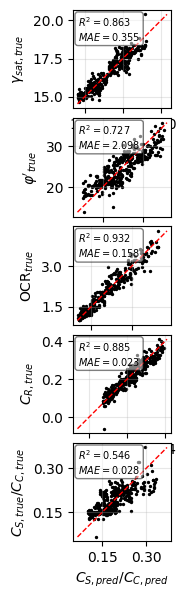

In [16]:
from matplotlib.ticker import MaxNLocator
# Inverse PCE: number of outputs = soil params
n_out = len(param_names)

fig, axes = plt.subplots(n_out, 1, figsize=(9*cm, 5*3*cm))
if n_out == 1:
    axes = [axes]

output_labels1 = {
"depth": "depth (m)",
"gamma": "$\gamma_{sat,pred}$",
"phi": "$\\varphi'_{pred}$",
"ocr": "OCR$_{pred}$",
"cr": "$C_{R,pred}$",
"cs_cc": "$C_{S,pred}/C_{C,pred}$",
}

output_labels2 = {
"depth": "depth (m)",
"gamma": "$\gamma_{sat,true}$",
"phi": "$\\varphi'_{true}$",
"ocr": "OCR$_{true}$",
"cr": "$C_{R,true}$",
"cs_cc": "$C_{S,true}/C_{C,true}$",
}

# Use latex_names for inverse outputs (soil params)
output_labels = {k: latex_names.get(k, k) for k in param_names}

for idx, out_name in enumerate(param_names):
    ax = axes[idx]
    actual = out_test[out_name]
    predicted = prediction_pce[out_name]
    
    # Calculate R²
    ss_res = np.sum((actual - predicted) ** 2)
    ss_tot = np.sum((actual - np.mean(actual)) ** 2)
    r2 = 1 - (ss_res / ss_tot) if ss_tot > 1e-12 else 0.0
    
    # Calculate RMSE
    # MAE instead of RMSE
    mae = np.mean(np.abs(actual - predicted))
    
    # Scatter plot
    ax.scatter(actual, predicted, s=2, color='k')
    
    # 1:1 line (perfect prediction)
    min_val = min(np.min(actual), np.min(predicted))
    max_val = max(np.max(actual), np.max(predicted))
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=1, label='1:1 line')

    # --- ADDED: Error Text Box ---
    stats_text = f"$R^2 = {r2:.3f}$\n$MAE = {mae:.3f}$"
    # Place text in the top-left (0.05, 0.95) using axes coordinates
    ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, 
            verticalalignment='top', horizontalalignment='left',
            fontsize=7, bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
    # -----------------------------
    
    # Labels and title
    lbl1 = output_labels1.get(out_name, out_name)
    lbl2 = output_labels2.get(out_name, out_name)
    ax.set_xlabel(f'{lbl1}')
    ax.set_ylabel(f'{lbl2}')
    ax.grid(True, alpha=0.3)
    
    # Make axes equal for better visualization
    ax.set_aspect('equal', adjustable='box')

    # Force exactly 3 ticks
    ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=3))

    # ax.set_xlim(xmin=0)
    # ax.set_ylim(ymin=0)

    # plt.tight_layout()

    plt.subplots_adjust(left=0.0, bottom=0.1, right=0.99, top=1, wspace=0.0, hspace=0.1)
    plt.savefig(PLOTS_DIR / "actual_vs_predicted_pce_depth_based_inverse.jpeg", dpi=1000)


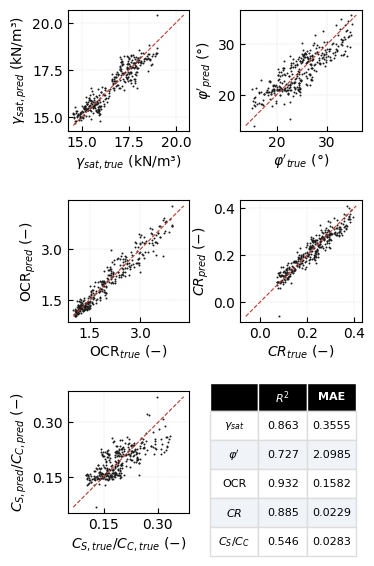

In [17]:
cm = 1 / 2.54

# ── Labels ────────────────────────────────────────────────────────────────────
output_labels_true = {
    "gamma": r"$\gamma_{sat,true}$ (kN/m³)",
    "phi":   r"$\varphi'_{true}$ (°)",
    "ocr":   r"OCR$_{true}$ (−)",
    "cr":    r"$CR_{true}$ (−)",
    "cs_cc": r"$C_{S,true}/C_{C,true}$ (−)",
}
output_labels_pred = {
    "gamma": r"$\gamma_{sat,pred}$ (kN/m³)",
    "phi":   r"$\varphi'_{pred}$ (°)",
    "ocr":   r"OCR$_{pred}$ (−)",
    "cr":    r"$CR_{pred}$ (−)",
    "cs_cc": r"$C_{S,pred}/C_{C,pred}$ (−)",
}
param_display = {
    "gamma": r"$\gamma_{sat}$",
    "phi":   r"$\varphi'$",
    "ocr":   r"OCR",
    "cr":    r"$CR$",
    "cs_cc": r"$C_S/C_C$",
}

BLACK = "#1a1a1a"
RED   = "#c0392b"

# ── Figure: 2×3 layout ───────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 2, figsize=(9 * cm, 3 * 5 * cm))
axes_flat = axes.flatten()  # (a)–(e) scatter, (f) table

r2_vals  = {}
mae_vals = {}

for idx, pname in enumerate(param_names):
    ax = axes_flat[idx]

    actual    = out_test[pname]
    predicted = prediction_pce[pname]

    # metrics
    ss_res = np.sum((actual - predicted) ** 2)
    ss_tot = np.sum((actual - np.mean(actual)) ** 2)
    r2  = 1 - ss_res / ss_tot if ss_tot > 1e-12 else 0.0
    mae = np.mean(np.abs(actual - predicted))
    r2_vals[pname]  = r2
    mae_vals[pname] = mae

    # scatter
    ax.scatter(actual, predicted, s=2, color=BLACK,
               alpha=1, linewidths=0, rasterized=True)

    # 1:1 line
    lo = min(actual.min(), predicted.min())
    hi = max(actual.max(), predicted.max())
    ax.plot([lo, hi], [lo, hi], color=RED, lw=0.8, ls="--")

    # # stats box
    # ax.text(0.05, 0.95,
    #         f"$R^2 = {r2:.3f}$\n$\\mathrm{{MAE}} = {mae:.3f}$",
    #         transform=ax.transAxes,
    #         va="top", ha="left", fontsize=5.5,
    #         bbox=dict(boxstyle="round,pad=0.3",
    #                   facecolor="white", edgecolor="0.75",
    #                   alpha=0.85, linewidth=0.4))

    ax.set_xlabel(output_labels_true[pname], labelpad=2)
    ax.set_ylabel(output_labels_pred[pname], labelpad=2)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, linestyle="--", linewidth=0.35, alpha=0.4)
    ax.tick_params(direction="in")
    ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=3))

    # # panel label
    # ax.text(0.97, 0.05, f"({chr(97 + idx)})",
    #         transform=ax.transAxes,
    #         fontsize=6, fontweight="bold",
    #         va="bottom", ha="right")

# ── 6th panel: R² and MAE table ───────────────────────────────────────────────
ax_tbl = axes_flat[5]
ax_tbl.axis("off")

col_labels = ["", r"$R^2$", "MAE"]
cell_text  = [
    [param_display[p], f"{r2_vals[p]:.3f}", f"{mae_vals[p]:.4f}"]
    for p in param_names
]

tbl = ax_tbl.table(
    cellText=cell_text,
    colLabels=col_labels,
    cellLoc="center",
    bbox=[-0.25, -0.1, 1.2, 1],  # [x0, y0, width, height] in Axes-Koordinaten
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(8)

# header styling
for j in range(len(col_labels)):
    tbl[0, j].set_facecolor("#000000")
    tbl[0, j].set_text_props(color="white", fontweight="bold")
    tbl[0, j].set_edgecolor("white")

# alternating row shading
for i in range(1, len(param_names) + 1):
    fc = "#f0f4f8" if i % 2 == 0 else "white"
    for j in range(len(col_labels)):
        tbl[i, j].set_facecolor(fc)
        tbl[i, j].set_edgecolor("#dddddd")

# panel label
# ax_tbl.text(0.78, 0.90, "(f)",
#             transform=ax_tbl.transAxes,
#             fontsize=6, fontweight="bold",
#             va="top", ha="right")
# ── spacing ───────────────────────────────────────────────────────────────────
plt.subplots_adjust(
    left=0.16, right=0.99,
    bottom=0.04, top=0.98,
    wspace=0.42, hspace=0.1,
)

fig.savefig(PLOTS_DIR / "actual_vs_predicted_pce_depth_based_inverse.png", dpi=1000)

In [18]:
metrics_df = pd.DataFrame(evaluation_results).T
print("\n" + "=" * 60)
print("SUMMARY OF EVALUATION METRICS")
print("=" * 60)
print(metrics_df.to_string())



SUMMARY OF EVALUATION METRICS
             R²      RMSE       MAE  NRMSE (range)  NRMSE (std)  LOO RMSE   LOO MSE
gamma  0.862568  0.441021  0.355459       0.098949     0.370139  0.522691  0.273206
phi    0.727195  2.486487  2.098489       0.125550     0.521491  2.946947  8.684496
ocr    0.931959  0.206037  0.158245       0.069862     0.260439  0.244192  0.059630
cr     0.884817  0.028610  0.022885       0.088128     0.338856  0.033909  0.001150
cs_cc  0.545898  0.035596  0.028297       0.153326     0.672817  0.042187  0.001780


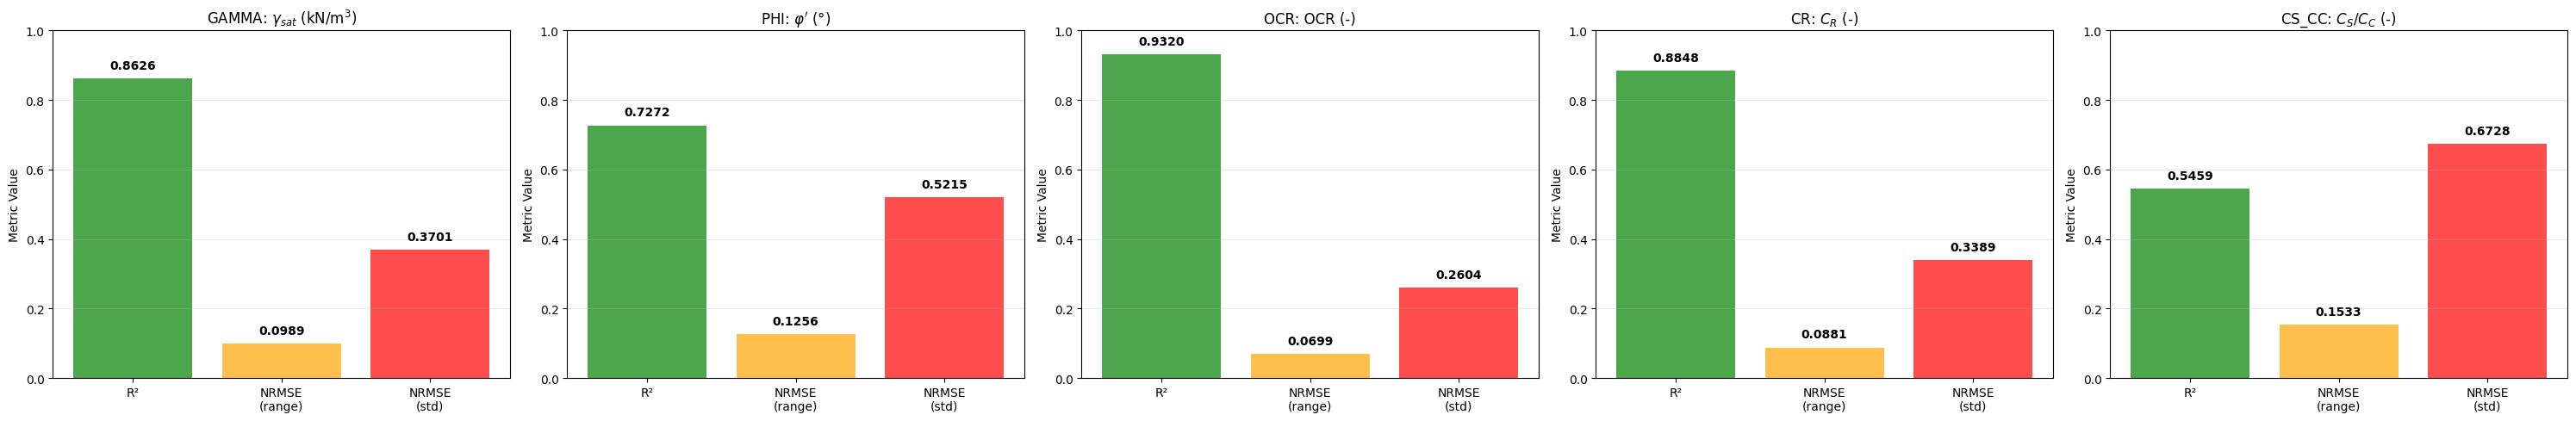

In [19]:
# Plot error metrics comparison (inverse PCE: outputs = param_names)
n_out = len(param_names)
fig, axes = plt.subplots(1, n_out, figsize=(6 * n_out, 5))
if n_out == 1:
    axes = [axes]
outputs = param_names
output_labels = [latex_names.get(o, o) for o in outputs]

for idx, (out_name, out_label) in enumerate(zip(outputs, output_labels)):
    ax = axes[idx]
    
    metrics = evaluation_results[out_name]
    
    # Create bar plot of key metrics
    metric_names = ["R²", "NRMSE\n(range)", "NRMSE\n(std)"]
    metric_values = [
        metrics["R²"],
        metrics["NRMSE (range)"],
        metrics["NRMSE (std)"],
    ]
    
    bars = ax.bar(metric_names, metric_values, alpha=0.7, color=['green', 'orange', 'red'])
    ax.set_ylabel("Metric Value")
    ax.set_title(f"{out_name.upper()}: {out_label}")
    ax.set_ylim(0, 1.0)
    ax.grid(True, alpha=0.3, axis="y")
    
    # Add value labels on bars
    for bar, val in zip(bars, metric_values):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{val:.4f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
# plt.savefig(PLOTS_DIR / "pce_depth_based_error_metrics.png", dpi=150, bbox_inches="tight")
plt.show()


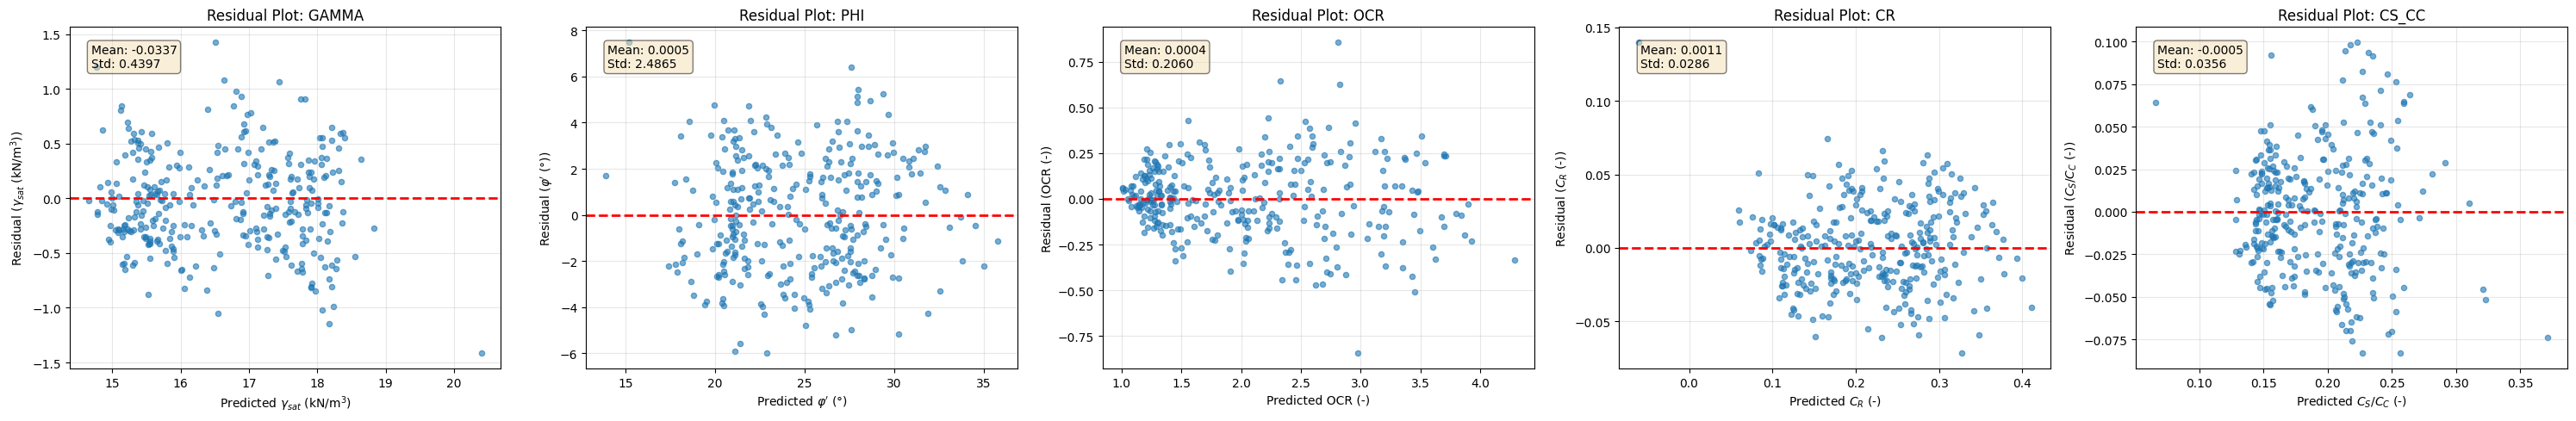

In [20]:
# Plot residuals (inverse PCE: outputs = param_names)
n_out = len(param_names)
fig, axes = plt.subplots(1, n_out, figsize=(6 * n_out, 5))
if n_out == 1:
    axes = [axes]
outputs = param_names
output_labels = [latex_names.get(o, o) for o in outputs]

for idx, (out_name, out_label) in enumerate(zip(outputs, output_labels)):
    ax = axes[idx]
    
    actual = out_test[out_name]
    predicted = prediction_pce[out_name]
    residuals = actual - predicted
    
    ax.scatter(predicted, residuals, alpha=0.6, s=20)
    ax.axhline(y=0, color='r', linestyle='--', linewidth=2)
    ax.set_xlabel(f"Predicted {out_label}")
    ax.set_ylabel(f"Residual ({out_label})")
    ax.set_title(f"Residual Plot: {out_name.upper()}")
    ax.grid(True, alpha=0.3)
    
    # Add statistics text
    mean_residual = np.mean(residuals)
    std_residual = np.std(residuals)
    ax.text(0.05, 0.95, f"Mean: {mean_residual:.4f}\nStd: {std_residual:.4f}",
            transform=ax.transAxes, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
# plt.savefig(PLOTS_DIR / "pce_depth_based_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
meta_opts = {
    "Type": "Metamodel",
    "Input": my_input["Name"],
    "MetaType": "PCE",
    "Degree": 6,
    "Method": method,
    "Display": "quiet",
    "ExpDesign": {
        "X": ed.values.tolist(),
        "Y": out.values.tolist()  
    }
}

final_pce = uq.createModel(meta_opts)

In [22]:
pce_int = final_pce["PCE"]
print("type:", type(pce_int))
print("length:", len(pce_int))

# Access first output
print("First element keys:", pce_int[0].keys())
print("Coefficients shape:", np.array(pce_int[0]["Coefficients"]).shape)
print("Indices shape:",      np.array(pce_int[0]["Basis"]["Indices"]).shape)

type: <class 'list'>
length: 5
First element keys: dict_keys(['Basis', 'Coefficients', 'Moments'])
Coefficients shape: (210,)
Indices shape: (210, 4)


In [23]:
prediction_test = uq.evalModel(final_pce, ed.values.tolist())
        
# Calculate average R² on test set
r2_values = []
for out_idx, out_name in enumerate(param_names):
    actual = out.values[:, out_idx]                    # true parameters
    predicted = prediction_test[:, out_idx].flatten() # predicted parameters
    r2 = calculate_r2(actual, predicted)
    r2_values.append(r2)

avg_r2 = np.mean(r2_values)

avg_r2 = np.mean(r2_values)
r2_str = ", ".join([f"{c}={v:.6f}" for c, v in zip(output_var_names, r2_values)])
print(f"Avg R² (physical, test set): {avg_r2:.6f} ({r2_str})")

Avg R² (physical, test set): 0.795318 (gamma=0.883303, phi=0.717158, ocr=0.932309, cr=0.888406, cs_cc=0.555416)


In [24]:
# --- 1. Build grouped soil consistencies from the test database ---

# Adjust to your file/sheet if needed (can reuse the same as in forward model)
DATA_SUBDIR = "02_database"
DATA_FILE_NAME = "GPFEM_database_20260414.xlsx"
DATA_SHEET_NAME = "Testdata"

df_summary_inv = pd.read_excel(
    DATA_DIR / DATA_SUBDIR / DATA_FILE_NAME,
    sheet_name=DATA_SHEET_NAME,
    skiprows=1,
)

In [25]:
df_summary_inv

,z [m],γ [kN/m3],φ' [deg],OCR,Rint,CR,cs/cc,ʋᵤᵣ,Unnamed: 8,Unnamed: 9,...,Initial_Water\n_Pressure,Contact_\nFriction_Angle,Unnamed: 30,qt_kPa,fs_kPa,u2_kPa,Qt_normalized,fs_normalized,U_normalized,remark
0,16.341303,18.912049,33.302699,3.477466,0.8,0.099238,0.168046,0.15,NaN,NaN,...,-163.41,27.72,NaN,2088.732940,85.450797,830.048918,12.220648,0.586766,4.577621,NaN
1,17.889273,18.812232,30.140090,3.590894,0.8,0.132814,0.177534,0.15,NaN,NaN,...,-178.89,24.91,NaN,2087.060688,79.707799,735.492749,11.104610,0.505632,3.530847,NaN
2,15.926177,17.629219,34.698508,3.826535,0.8,0.110066,0.234777,0.15,NaN,NaN,...,-159.26,28.98,NaN,1755.108914,72.602704,669.351290,12.134559,0.597553,4.198282,NaN
3,19.701498,18.105414,32.660796,3.043636,0.8,0.091658,0.192478,0.15,NaN,NaN,...,-197.01,27.15,NaN,2043.855206,69.551354,824.753660,10.565190,0.435540,3.931014,NaN
4,15.331814,17.015201,34.165837,3.747717,0.8,0.111972,0.189231,0.15,NaN,NaN,...,-153.32,28.50,NaN,1608.179355,68.158343,642.033598,12.526026,0.633677,4.543637,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,5.293691,15.015672,15.707821,1.095906,0.8,0.396753,0.176881,0.15,NaN,NaN,...,-52.94,12.68,NaN,135.221341,2.387219,86.812704,2.099109,0.089914,1.275808,NaN
796,5.719315,15.422987,22.203231,1.027662,0.8,0.253189,0.147648,0.15,NaN,NaN,...,-57.19,18.08,NaN,175.694819,2.384576,109.305720,2.820271,0.076872,1.680068,NaN
797,5.719315,14.922987,19.203231,1.013831,0.8,0.329783,0.130197,0.15,NaN,NaN,...,-57.19,15.57,NaN,155.413420,2.381962,99.602329,2.488048,0.084587,1.506120,NaN
798,5.332066,15.140757,23.914900,1.093380,0.8,0.356737,0.179894,0.15,NaN,NaN,...,-53.32,19.53,NaN,159.097958,2.258189,95.906126,2.859101,0.082386,1.553671,NaN


In [26]:
# df_summary_inv already loaded from Testdata, e.g.
# df_summary_inv = pd.read_excel(...)

# 1) Build X from df_summary_inv in the SAME order used to train inverse PCE
cols_X = ["z [m]", "qt_kPa", "fs_kPa", "u2_kPa"]   # change if you used different inputs
X_inv = df_summary_inv[cols_X].to_numpy(float)

# 2) Evaluate the trained inverse PCE on these CPT outputs
# Replace 'final_pce_inverse' by your actual inverse PCE model variable
Y_pred_inv = np.array(uq.evalModel(final_pce, X_inv.tolist()))  # (N, n_params)
# df_pred_inv_phys = unscale_from_logit(Y_pred_inv, bounds, output_var_names)

param_names = ["γ [kN/m3]", "φ' [deg]", "OCR", "CR", "cs/cc"] 

true_series = [df_summary_inv[name].to_numpy(float) for name in param_names]
pred_series = [Y_pred_inv[:, j] for j in range(len(param_names))]
# pred_series = [df_pred_inv_phys[c].to_numpy(float) for c in output_var_names]

In [27]:
# 3) Soil consistency + depth from the SAME dataframe
import re
soil_consistency_raw = df_summary_inv["Series_Name"].to_numpy(object)
depth_values_inv = df_summary_inv["z [m]"].to_numpy(float)

def base_consistency(label: str) -> str:
    m = re.match(r"([A-Za-z]+)", str(label))
    return m.group(1).lower() if m else str(label).lower()

soil_consistency_group = np.array([base_consistency(s) for s in soil_consistency_raw])

In [28]:
target_groups = ["verysoft", "soft", "medium", "stiff"]  # adjust to what you saw above
unique_consistencies = [g for g in target_groups if g in soil_consistency_group]

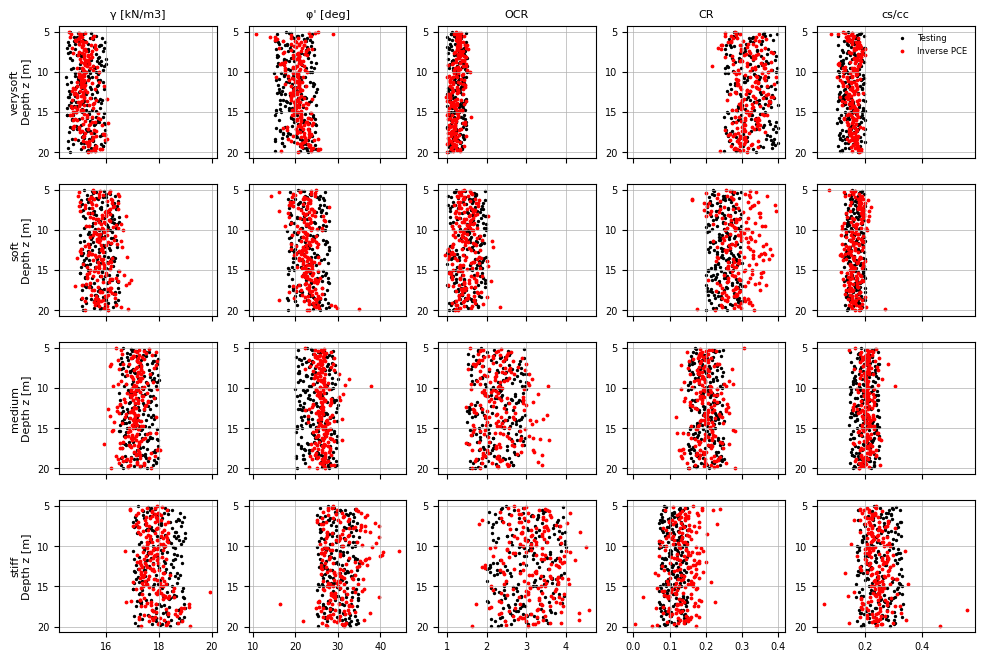

In [29]:
n_groups = len(unique_consistencies)
n_params = len(param_names)

fig, axes = plt.subplots(
    nrows=n_groups, ncols=n_params,
    figsize=(n_params * 6 * cm, n_groups * 5 * cm),
    sharex='col', sharey=False
)
if n_groups == 1:
    axes = np.array([axes])

for i, cons in enumerate(unique_consistencies):
    mask = (soil_consistency_group == cons)  # length = number of rows in df_summary_inv

    for j, pname in enumerate(param_names):
        ax = axes[i, j]
        y_depth = depth_values_inv[mask]
        x_true = true_series[j][mask]
        x_pred = pred_series[j][mask]

        # Sort by depth
        sort_idx = np.argsort(y_depth)
        y_sorted = y_depth[sort_idx]
        x_true_sorted = x_true[sort_idx]
        x_pred_sorted = x_pred[sort_idx]

        ax.scatter(x_true_sorted, y_sorted, s=2, c="k", label="Testing")
        ax.scatter(x_pred_sorted, y_sorted, s=3, c="r", label="Inverse PCE")
        ax.grid(lw=0.5)
        ax.invert_yaxis()

        if i == 0:
            ax.set_title(pname, fontsize=8)
        if j == 0:
            ax.set_ylabel(f"{cons}\nDepth z [m]", fontsize=8)
        ax.tick_params(labelsize=7)
        if i == 0 and j == n_params - 1:
            ax.legend(fontsize=6, loc="upper right", frameon=False)


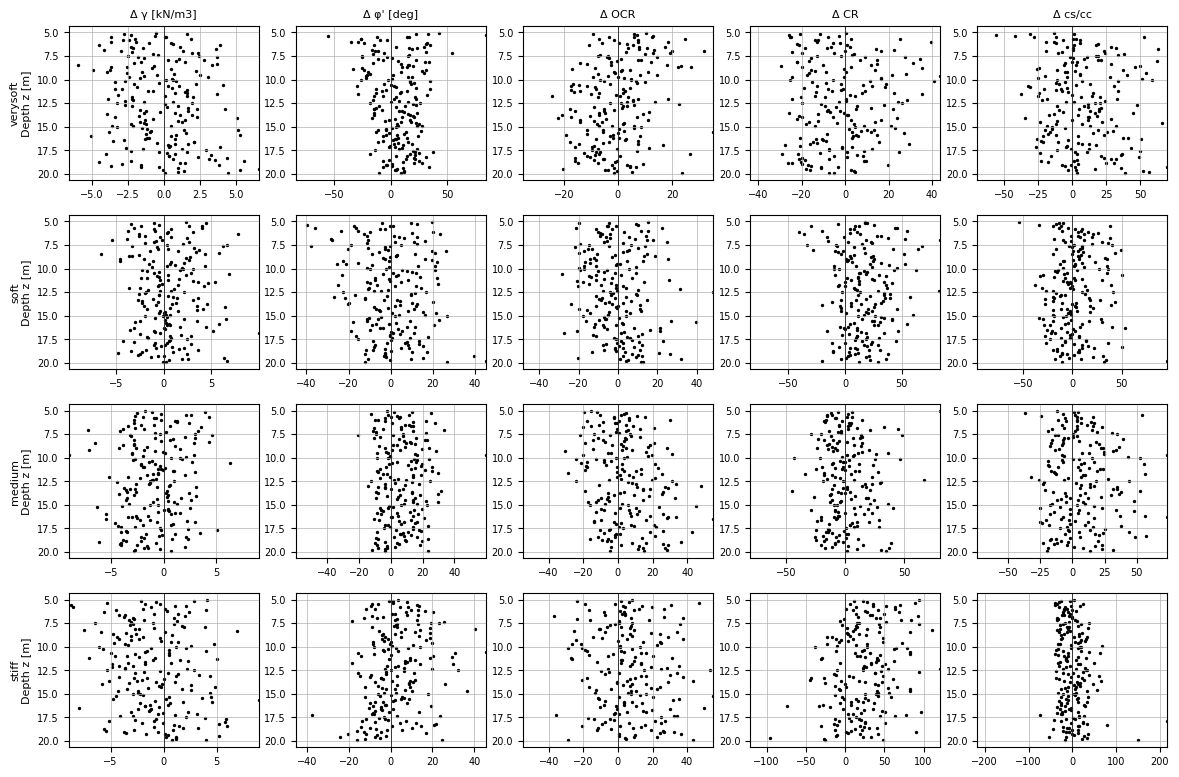

In [30]:
# --- Residual plots: inverse PCE error vs depth per consistency and parameter ---

# residual = PCE - Testing (absolute error)
residual_series_inv = [
    (pred_series[j] - true_series[j])/true_series[j]*100 for j in range(len(param_names))
]

n_groups = len(unique_consistencies)
n_params = len(param_names)

fig_res_inv, axes_res_inv = plt.subplots(
    nrows=n_groups, ncols=n_params,
    figsize=(n_params * 6 * cm, n_groups * 5 * cm),
    sharex=False, sharey=False,
)
if n_groups == 1:
    axes_res_inv = np.array([axes_res_inv])

for i, cons in enumerate(unique_consistencies):
    mask = (soil_consistency_group == cons)

    for j, pname in enumerate(param_names):
        ax = axes_res_inv[i, j]
        y_depth = depth_values_inv[mask]
        err = residual_series_inv[j][mask]

        sort_idx = np.argsort(y_depth)
        y_sorted = y_depth[sort_idx]
        err_sorted = err[sort_idx]

        ax.scatter(err_sorted, y_sorted, s=2, c="k")
        ax.axvline(0.0, color="k", lw=0.5)  # zero-error line
        ax.grid(lw=0.5)
        ax.invert_yaxis()
        # Optional: symmetric x-limits around 0
        err_max = np.max(np.abs(err_sorted)) if err_sorted.size > 0 else 1.0
        ax.set_xlim(left=-err_max, right=err_max)
        # Adapt depth limits if needed
        # ax.set_ylim(ymax=5, ymin=20)

        if i == 0:
            ax.set_title(f"Δ {pname}", fontsize=8)
        if j == 0:
            ax.set_ylabel(f"{cons}\nDepth z [m]", fontsize=8)
        ax.tick_params(labelsize=7)

plt.tight_layout()
plt.show()

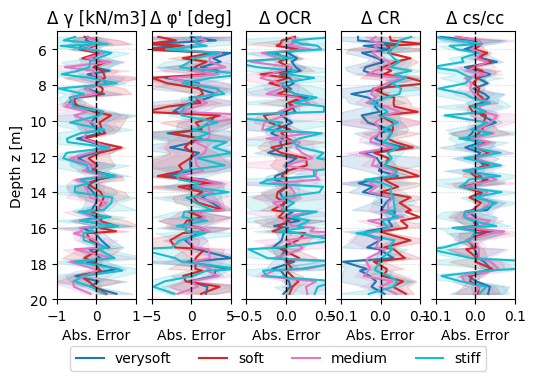

In [31]:
# 1. Compute Absolute Error (Residual = Predicted - True)
residual_series_inv = [
    (pred_series[j] - true_series[j]) for j in range(len(param_names))
]

# Colors
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_consistencies)))

# Figure
fig, axes = plt.subplots(1, 5, figsize=(3 * 5 * cm, 10 * cm), sharey=True)

# ---- LOOP OVER PARAMETERS (ONE AXIS PER PARAMETER) ----
for j, (ax, pname) in enumerate(zip(axes, param_names)):

    all_means = []
    all_vals = []

    # ---- LOOP OVER CONSISTENCIES ----
    for i, cons in enumerate(unique_consistencies):

        mask = (soil_consistency_group == cons)

        y_depth = depth_values_inv[mask]
        err = residual_series_inv[j][mask]

        df_temp = pd.DataFrame({
            'depth': y_depth,
            'error': err
        })

        # depth binning (0.1 m)
        stats = (
            df_temp
            .groupby(df_temp['depth'].round(1))['error']
            .agg(['mean', 'std'])
            .dropna()
        )

        # std band
        ax.fill_betweenx(
            stats.index,
            stats['mean'] - stats['std'],
            stats['mean'] + stats['std'],
            color=colors[i],
            alpha=0.15
        )

        # mean line
        ax.plot(
            stats['mean'],
            stats.index,
            color=colors[i],
            lw=1.5,
            label=cons if j == 0 else None  # avoid duplicate legend entries
        )

        all_means.extend(stats['mean'].values)

                # im inneren Loop ergänzen:
        all_vals.extend((stats['mean'] + stats['std']).values)
        all_vals.extend((stats['mean'] - stats['std']).values)

        # nach dem Loop:
        if len(all_vals) > 0:
            max_abs = np.max(np.abs(all_vals))
            ax.set_xlim(-max_abs, max_abs)

    # ---- Styling ----
    ax.axvline(0.0, color="k", lw=1, ls="--")
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.invert_yaxis()

    ax.set_ylim(20, 5)
    ax.set_xlabel("Abs. Error")
    ax.set_title(f"Δ {pname}")

    if j == 0:
        ax.set_ylabel("Depth z [m]")

# ---- Global legend ----
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.0),
    ncol=len(unique_consistencies),
    frameon=True
)

axes[0].set_xlim(-1, 1)
axes[1].set_xlim(-5, 5)
axes[2].set_xlim(-0.5, .5)
axes[3].set_xlim(-0.1, .1)
axes[4].set_xlim(-0.1, .1)

plt.subplots_adjust(wspace=0.2, bottom=0.2)

Parameter: γ [kN/m3], Consistencies: ['verysoft', 'soft', 'medium', 'stiff']
Parameter: φ' [deg], Consistencies: ['verysoft', 'soft', 'medium', 'stiff']
Parameter: OCR, Consistencies: ['verysoft', 'soft', 'medium', 'stiff']
Parameter: CR, Consistencies: ['verysoft', 'soft', 'medium', 'stiff']
Parameter: cs/cc, Consistencies: ['verysoft', 'soft', 'medium', 'stiff']


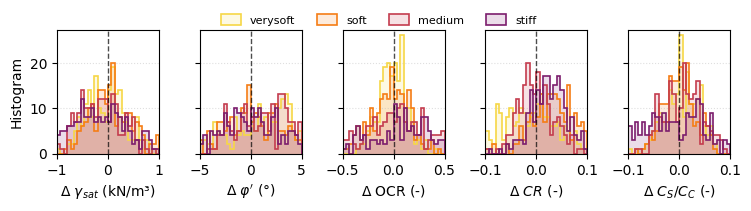

In [32]:
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors


param_display = {
    "γ [kN/m3]": r"$\Delta~\gamma_{sat}$ (kN/m³)",
    "φ' [deg]":   r"$\Delta~\varphi'$ (°)",
    "OCR":   r"$\Delta$ OCR (-)",
    "CR":    r"$\Delta~CR$ (-)",
    "cs/cc": r"$\Delta~C_S/C_C$ (-)",
}

# 1. Compute Absolute Error
residual_series_inv = [
    (pred_series[j] - true_series[j]) for j in range(len(param_names))
]

# Specific x-limits from your requirements
x_lims = [(-1, 1), (-5, 5), (-0.5, 0.5), (-0.1, 0.1), (-0.1, 0.1)]

colors = plt.cm.inferno(np.linspace(0.9, 0.34, len(unique_consistencies)))

# Figure (Now 1 row, independent y-axis for counts)
fig, axes = plt.subplots(1, 5, figsize=(19 * cm, 5 * cm), sharey=True)

# ---- LOOP OVER PARAMETERS ----
for j, (ax, pname) in enumerate(zip(axes, param_names)):

    # ---- LOOP OVER CONSISTENCIES (HISTOGRAMS) ----
    for i, cons in enumerate(unique_consistencies):
        mask = (soil_consistency_group == cons)
        err = residual_series_inv[j][mask]

        # Stepfilled for the background tint
        ax.hist(
            err, bins=30, range=x_lims[j],
            histtype='stepfilled', color=colors[i], alpha=0.15,
        )
        
        # Step for the bold outline
        ax.hist(
            err, bins=30, range=x_lims[j],
            histtype='step', color=colors[i], lw=1.2,
            label=cons if j == 0 else None
        )

    # ---- Styling to match reference image ----
    ax.axvline(0.0, color="k", lw=1, ls="--", alpha=0.7)
    ax.grid(True, axis='y', linestyle=':', alpha=0.4)
    
    print(f"Parameter: {pname}, Consistencies: {unique_consistencies}")
    ax.set_xlim(x_lims[j])
    ax.set_xlabel(param_display[pname])

    if j == 0:
        ax.set_ylabel("Histogram")



# ---- Global legend at the bottom ----
legend_handles = []

for i, cons in enumerate(unique_consistencies):
    # Create a version of the color with 0.15 alpha for the face
    # and use the original full-opacity color for the edge
    face_col = mcolors.to_rgba(colors[i], alpha=0.15)
    edge_col = mcolors.to_rgba(colors[i], alpha=1.0)
    
    patch = mpatches.Patch(
        facecolor=face_col, 
        edgecolor=edge_col, 
        linewidth=1.2, 
        label=cons
    )
    legend_handles.append(patch)

fig.legend(
    handles=legend_handles, 
    loc='lower center', 
    bbox_to_anchor=(0.5, 0.85), 
    ncol=len(unique_consistencies),
    frameon=False,
    handleheight=1.2,
    handlelength=1.8,
    fontsize=8
)

plt.subplots_adjust(wspace=0.4, bottom=0.25, left=0.07, right=0.97)
plt.savefig(PLOTS_DIR / "pce_depth_based_residual_histograms.png", dpi=1000)

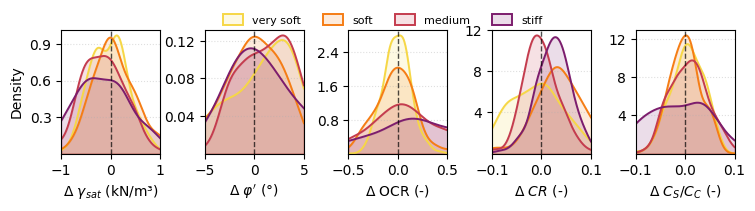

In [33]:
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from scipy.stats import gaussian_kde

param_display = {
    "γ [kN/m3]": r"$\Delta~\gamma_{sat}$ (kN/m³)",
    "φ' [deg]":   r"$\Delta~\varphi'$ (°)",
    "OCR":   r"$\Delta$ OCR (-)",
    "CR":    r"$\Delta~CR$ (-)",
    "cs/cc": r"$\Delta~C_S/C_C$ (-)",
}

# 1. Compute Absolute Error
residual_series_inv = [
    (pred_series[j] - true_series[j]) for j in range(len(param_names))
]

# Specific x-limits from your requirements
x_lims = [(-1, 1), (-5, 5), (-0.5, 0.5), (-0.1, 0.1), (-0.1, 0.1)]

colors = plt.cm.inferno(np.linspace(0.9, 0.34, len(unique_consistencies)))

# Figure
fig, axes = plt.subplots(1, 5, figsize=(19 * cm, 5 * cm), sharey=False)  # sharey=False — density scales differ per param

# ---- LOOP OVER PARAMETERS ----
for j, (ax, pname) in enumerate(zip(axes, param_names)):

    # ---- LOOP OVER CONSISTENCIES (KDE) ----
    for i, cons in enumerate(unique_consistencies):
        mask = (soil_consistency_group == cons)
        err = residual_series_inv[j][mask]

        # Need enough data points for KDE
        if len(err) < 3:
            continue

        # Evaluate KDE over a fine grid clipped to x_lims
        x_grid = np.linspace(x_lims[j][0], x_lims[j][1], 400)
        kde = gaussian_kde(err, bw_method='scott')
        density = kde(x_grid)

        # Filled area (light tint)
        ax.fill_between(x_grid, density, alpha=0.15, color=colors[i])

        # Bold outline
        ax.plot(x_grid, density, color=colors[i], lw=1.4,
                label=cons if j == 0 else None)

    # ---- Styling ----
    ax.axvline(0.0, color="k", lw=1, ls="--", alpha=0.7)
    ax.grid(True, axis='y', linestyle=':', alpha=0.4)

    ax.set_xlim(x_lims[j])
    ax.set_xlabel(param_display[pname])
    ax.set_ylim(bottom=0)

    # Clean up y-axis ticks to avoid clutter across different density scales
    ax.yaxis.set_major_locator(plt.MaxNLocator(4, prune='both'))

    if j == 0:
        ax.set_ylabel("Density")


# ---- Global legend at the bottom ----
legend_handles = []

for i, cons in enumerate(unique_consistencies):
    face_col = mcolors.to_rgba(colors[i], alpha=0.15)
    edge_col = mcolors.to_rgba(colors[i], alpha=1.0)

    display_label = "very soft" if cons == "verysoft" else cons  # ← rename here

    patch = mpatches.Patch(
        facecolor=face_col,
        edgecolor=edge_col,
        linewidth=1.4,
        label=display_label
    )
    legend_handles.append(patch)

fig.legend(
    handles=legend_handles,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.85),
    ncol=len(unique_consistencies),
    frameon=False,
    handleheight=1.2,
    handlelength=1.8,
    fontsize=8
)

plt.subplots_adjust(wspace=0.45, bottom=0.25, left=0.07, right=0.97)
plt.savefig(PLOTS_DIR / "pce_depth_based_residual_densities.png", dpi=1000)

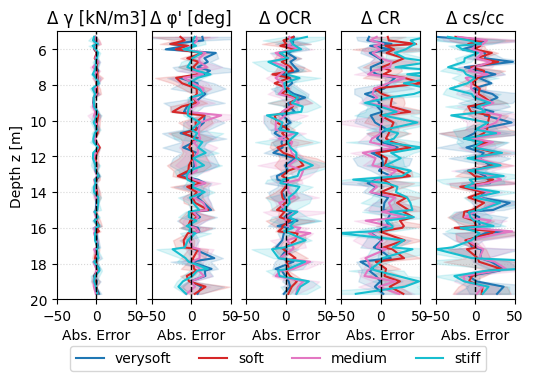

In [34]:
# 1. Compute Absolute Error (Residual = Predicted - True)
residual_series_inv = [
    (pred_series[j] - true_series[j])/true_series[j]*100 for j in range(len(param_names))
]

# Colors
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_consistencies)))

# Figure
fig, axes = plt.subplots(1, 5, figsize=(3 * 5 * cm, 10 * cm), sharey=True)

# ---- LOOP OVER PARAMETERS (ONE AXIS PER PARAMETER) ----
for j, (ax, pname) in enumerate(zip(axes, param_names)):

    all_means = []

    # ---- LOOP OVER CONSISTENCIES ----
    for i, cons in enumerate(unique_consistencies):

        mask = (soil_consistency_group == cons)

        y_depth = depth_values_inv[mask]
        err = residual_series_inv[j][mask]

        df_temp = pd.DataFrame({
            'depth': y_depth,
            'error': err
        })

        # depth binning (0.1 m)
        stats = (
            df_temp
            .groupby(df_temp['depth'].round(1))['error']
            .agg(['mean', 'std'])
            .dropna()
        )

        # std band
        ax.fill_betweenx(
            stats.index,
            stats['mean'] - stats['std'],
            stats['mean'] + stats['std'],
            color=colors[i],
            alpha=0.15
        )

        # mean line
        ax.plot(
            stats['mean'],
            stats.index,
            color=colors[i],
            lw=1.5,
            label=cons if j == 0 else None  # avoid duplicate legend entries
        )

        all_means.extend(stats['mean'].values)

    # ---- Styling ----
    ax.axvline(0.0, color="k", lw=1, ls="--")
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.invert_yaxis()

    ax.set_xlim(-50, 50)
    ax.set_ylim(20, 5)
    ax.set_xlabel("Abs. Error")
    ax.set_title(f"Δ {pname}")

    if j == 0:
        ax.set_ylabel("Depth z [m]")

# ---- Global legend ----
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.0),
    ncol=len(unique_consistencies),
    frameon=True
)

plt.subplots_adjust(wspace=0.2, bottom=0.2)

In [35]:
# --- 1) Test-case definition -------------------------------------------------
test_case_params = {
    "Lambda_Star": 0.0774,   # λ*
    "Kappa_Star":  0.0139,   # κ*
    "Friction_Angle": 25.0,  # φ' [deg]
    "OCR": 1.0,
    "K0": 0.58,
    "Initial_Sigma_V_Eff": {8: -33,  10: -42,  12: -53},
    "Initial_Sigma_H_Eff": {8: -19.1,10: -24.3, 12: -30.6},
    "Initial_Water_Pressure": {8: -85, 10: -105, 12: -125},
    "unit_weight": {8: 14.5, 10: 15.0, 12: 15.5},
    # "cpt_measurements": {
    #     8:  {"qt": 205, "fs": 1.4, "u2": 148},
    #     10: {"qt": 263, "fs": 2.3, "u2": 187},
    #     12: {"qt": 319, "fs": 3.5, "u2": 227},
    # },
    # Actual/measured outputs for comparison (optional; leave or update from measurements)
    "cpt_measurements": {
        8: {"qt": 213, "fs": 2.7, "u2": 144},    # qt, fs, u2 in kPa
        10: {"qt": 273, "fs": 3.9, "u2": 186},
        12: {"qt": 331, "fs": 6.1, "u2": 220},
    }
}

# depths used in the CPT test case
depths = sorted(test_case_params["unit_weight"].keys())  # [8, 10, 12]

print("Inverse test case – building inputs and true soil parameters")
print("=" * 70)

inverse_test_inputs = {}
inverse_true_params = {}

for z in depths:
    # CPT outputs at this depth (these are the inputs to inverse PCE)
    qt = test_case_params["cpt_measurements"][z]["qt"]
    fs = test_case_params["cpt_measurements"][z]["fs"]
    u2 = test_case_params["cpt_measurements"][z]["u2"]

    # Build 1D input array in the same order as ed.columns: [depth, qt, fs, u2]
    x_inv = np.array([float(z), float(qt), float(fs), float(u2)], dtype=float)

    inverse_test_inputs[z] = {
        "depth": z,
        "qt": qt,
        "fs": fs,
        "u2": u2,
        "input_array": x_inv,
    }

    # True soil parameters at this depth (what the inverse PCE should recover)
    # From your Cam–Clay relationships + test_case_params:
    lam_star = float(test_case_params["Lambda_Star"])   # λ*
    kap_star = float(test_case_params["Kappa_Star"])    # κ*

    CR        = 2.303 * lam_star
    cs_over_cc = kap_star / lam_star
    

    inverse_true_params[z] = {
        "gamma":  test_case_params["unit_weight"][z],
        "phi":    test_case_params["Friction_Angle"],
        "ocr":    test_case_params["OCR"],
        "cr":     CR,
        "cs_cc":  cs_over_cc,
    }

    print(f"Depth {z:>3} m: X = [z, qt, fs, u2] = {x_inv},   true soil = {inverse_true_params[z]}")

print("\n" + "=" * 70)

Inverse test case – building inputs and true soil parameters
Depth   8 m: X = [z, qt, fs, u2] = [  8.  213.    2.7 144. ],   true soil = {'gamma': 14.5, 'phi': 25.0, 'ocr': 1.0, 'cr': 0.1782522, 'cs_cc': 0.17958656330749354}
Depth  10 m: X = [z, qt, fs, u2] = [ 10.  273.    3.9 186. ],   true soil = {'gamma': 15.0, 'phi': 25.0, 'ocr': 1.0, 'cr': 0.1782522, 'cs_cc': 0.17958656330749354}
Depth  12 m: X = [z, qt, fs, u2] = [ 12.  331.    6.1 220. ],   true soil = {'gamma': 15.5, 'phi': 25.0, 'ocr': 1.0, 'cr': 0.1782522, 'cs_cc': 0.17958656330749354}



In [36]:
print("Evaluating inverse PCE on test case...")
print("=" * 70)

inverse_predictions = {}

for z in depths:
    x = inverse_test_inputs[z]["input_array"]
    y_hat = np.asarray(uq.evalModel(final_pce, [x.tolist()]))  # shape (1, 5)

    inverse_predictions[z] = {
        name: float(y_hat[0, j])
        for j, name in enumerate(output_var_names)  # ['gamma','phi','ocr','cr','cs_cc']
    }

    print(f"Depth {z:>3} m: predicted = {inverse_predictions[z]}")

print("\n" + "=" * 70)

Evaluating inverse PCE on test case...
Depth   8 m: predicted = {'gamma': 14.811397927754117, 'phi': 16.419629427862397, 'ocr': 1.1226777419581246, 'cr': 0.40091209623239155, 'cs_cc': 0.11903380190252431}
Depth  10 m: predicted = {'gamma': 14.986861672228672, 'phi': 19.410854835788516, 'ocr': 0.9914960581270778, 'cr': 0.3314329847806139, 'cs_cc': 0.14724178349695777}
Depth  12 m: predicted = {'gamma': 15.163498238777077, 'phi': 19.24156204481096, 'ocr': 1.1386559740048594, 'cr': 0.22677354122366725, 'cs_cc': 0.18929138629816125}



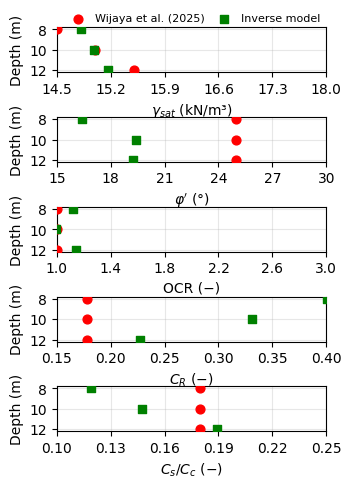

In [37]:
import matplotlib.pyplot as plt
from matplotlib.ticker import LinearLocator

params = output_var_names  # ['gamma','phi','ocr','cr','cs_cc']
labels = {
    "gamma": r"$\gamma_{sat}$ (kN/m³)",
    "phi":   r"$\varphi'$ (°)",
    "ocr":   r"OCR (−)",
    "cr":    r"$C_R$ (−)",
    "cs_cc": r"$C_s/C_c$ (−)",
}

# ── soft soil physical bounds ─────────────────────────────────────────────────
xlims = {
    "gamma": (14.5, 18.0),
    "phi":   (15.0, 30.0),
    "ocr":   (1.0, 3.0),
    "cr":    (0.15, 0.40),
    "cs_cc": (0.10, 0.25),
}

RED   = "#c0392b"
GREEN = "#27ae60"

n_p = len(params)
fig, axes = plt.subplots(n_p, 1, figsize=(9*cm, 12*cm))

if n_p == 1:
    axes = [axes]

for idx, pname in enumerate(params):
    ax = axes[idx]

    true_vals = [inverse_true_params[z][pname] for z in depths]
    pred_vals = [inverse_predictions[z][pname]  for z in depths]

    ax.scatter(true_vals, depths, color='red',   label="Wijaya et al. (2025)",
               s=40, marker="o", zorder=3)
    ax.scatter(pred_vals, depths, color='green', label="Inverse model",
               s=40, marker="s", zorder=3)

    ax.set_ylabel("Depth (m)")
    ax.set_xlabel(labels.get(pname, pname))
    ax.set_xlim(xlims[pname])                  # ← prescribed soft soil bounds
    # ax.set_ylim(15, 5)                       # depth increases downwards
    ax.invert_yaxis()
    ax.grid(True, alpha=0.3)
    ax.xaxis.set_major_locator(LinearLocator(6))

# axes[2].set_xticks([1.0, 1.05, 1.1])

# ── shared legend above all panels ───────────────────────────────────────────
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels_,
    loc="upper center",
    bbox_to_anchor=(0.57, 1.005),
    ncol=2,
    fontsize=8,
    frameon=False,
    framealpha=0.9,
    edgecolor="0.75",
    handlelength=1.5,
    columnspacing=1.0,
)

plt.subplots_adjust(
    left=0.18, bottom=0.1, right=0.94,
    top=0.955,
    hspace=1,
)

plt.savefig(PLOTS_DIR / "inverse_pce_test_case_depth_profiles.jpeg", dpi=1000)

In [38]:
cop = my_input['Copula']

In [39]:
cop

{'Type': 'CVine',
 'Dimension': 4,
 'Parameters': [5.98796183959415,
  [0.9728345738410278, 16.083781800870202],
  0.6329222458642899,
  -9.016429462994418,
  -13.723733446975775],
 'RankCorr': [],
 'cholR': [],
 'Family': [],
 'Rotation': [],
 'Structure': [2, 4, 3, 1],
 'Families': ['Gumbel', 't', 'Gaussian', 'Frank', 'Frank', 'Independent'],
 'Rotations': [0, 0, 0, 180, 90, 0],
 'Truncation': 2,
 'Pairs': [[2, 4], [2, 3], [2, 1], [4, 3], [4, 1], [3, 1]],
 'CondVars': [2, 2, [2, 4]],
 'Trees': [1, 1, 1, 2, 2, 3],
 'Variables': [1, 2, 3, 4],
 'Inference': {'Criterion': 'AIC',
  'PairIndepTest': {'Alpha': 0.1, 'Type': 'Kendall', 'Correction': 'auto'},
  'CVineStructure': 'auto',
  'DVineStructure': 'auto',
  'PCfamilies': ['Independent', 'Clayton', 'Frank', 'Gaussian', 'Gumbel', 't'],
  'Rotations': 'auto'},
 'GoF': {'Gaussian': {'LL': 7248.895346917324,
   'AIC': -14485.790693834648,
   'BIC': -14453.52414038528},
  'CVine': {'LL': 7314.933698328532,
   'AIC': -14629.867396657064,
   

In [40]:
# ═══════════════════════════════════════════════════════════════════════════════
# FINAL EXPORT — fully analytical Rosenblatt (no RBF needed)
# Run after the verification cell passes ALL PASS ✓
# ═══════════════════════════════════════════════════════════════════════════════
from scipy import stats

out_dir = Path('pce_exports')
out_dir.mkdir(exist_ok=True)

# ── 1. PCE terms (indices + coefficients) ─────────────────────────────────────
pce_int   = final_pce['PCE']
alpha_arr = np.array(pce_int[0]['Basis']['Indices'])   # (210, 4)
y_names   = ['gamma', 'phi', 'ocr', 'cr', 'cs_cc']

df_pce = pd.DataFrame(alpha_arr, columns=['alpha_z','alpha_qt','alpha_fs','alpha_u2'])
for j, name in enumerate(y_names):
    df_pce[f'c_{name}'] = np.array(pce_int[j]['Coefficients']).flatten()

df_pce.to_csv(out_dir / 'inverse_pce_terms.csv', index=False)
print(f'Exported inverse_pce_terms.csv:  {df_pce.shape}')

# ── 2. Input bounds (training data min/max) ───────────────────────────────────
x_names = ['z', 'qt', 'fs', 'u2']
bounds_df = pd.DataFrame({
    'variable': x_names,
    'lo': ed[['depth','qt','fs','u2']].min().values,
    'hi': ed[['depth','qt','fs','u2']].max().values,
})
bounds_df.to_csv(out_dir / 'inverse_bounds.csv', index=False)
print(f'Exported inverse_bounds.csv')
print(bounds_df.to_string(index=False))

# ── 3. Transform parameters (marginals + vine copula) ────────────────────────
d     = my_input['Marginals']
lo_z  = d[0]['Parameters'][0];  hi_z  = d[0]['Parameters'][1]
mu_qt = d[1]['Parameters'][0];  sg_qt = d[1]['Parameters'][1]
mu_fs = d[2]['Parameters'][0];  sg_fs = d[2]['Parameters'][1]
mu_u2 = d[3]['Parameters'][0];  sg_u2 = d[3]['Parameters'][1]

cop = my_input['Copula']
GUMBEL_THETA = float(cop['Parameters'][0])
T_RHO        = float(cop['Parameters'][1][0])
T_NU         = float(cop['Parameters'][1][1])
FRANK_FS     = float(cop['Parameters'][3])   # pair (u2,fs)|qt  tree-2
FRANK_Z      = abs(float(cop['Parameters'][4]))             # pair (u2,z)|qt   tree-2 [positive!]
RHO          = abs(float(cop['Parameters'][2]))             

transform_params = {
    'marginals': {
        'z':  {'type': 'uniform',   'lo': lo_z,  'hi': hi_z},
        'qt': {'type': 'lognormal', 'mu': mu_qt, 'sigma': sg_qt},
        'fs': {'type': 'lognormal', 'mu': mu_fs, 'sigma': sg_fs},
        'u2': {'type': 'lognormal', 'mu': mu_u2, 'sigma': sg_u2},
    },
    'vine': {
        'gumbel_theta': GUMBEL_THETA,  # pair (qt,u2)    tree-1
        't_rho':        T_RHO,          # pair (qt,fs)    tree-1
        't_nu':         T_NU,           # pair (qt,fs)    tree-1
        'frank_fs':     FRANK_FS,       # pair (u2,fs)|qt tree-2  [negative]
        'frank_z':      FRANK_Z,        # pair (u2,z)|qt  tree-2  [positive!]
        'gaussian_rho_z': RHO,          # pair (z,qt)      tree-1 (same as in rosenblatt)
    },
    'basis': {
        'z':  'legendre',   # u_z in [-1,1]:    sqrt(2n+1)*P_n(u_z)
        'qt': 'hermite',    # u_qt std-normal:  He_n(u)/sqrt(n!)
        'fs': 'hermite',
        'u2': 'hermite',
    }
}

with open(out_dir / 'inv_transform_params.json', 'w') as f:
    json.dump(transform_params, f, indent=2)
print(f'Exported inv_transform_params.json')

# ── 4. Quick verification with exported files ─────────────────────────────────
def h_gumbel(v,u,theta):
    u,v=np.clip(u,1e-10,1-1e-10),np.clip(v,1e-10,1-1e-10)
    lu=-np.log(u); lv=-np.log(v); s=lu**theta+lv**theta
    return float(np.exp(-s**(1/theta))*(1/u)*lu**(theta-1)*s**(1/theta-1))
def h_t(v,u,rho,nu):
    u,v=np.clip(u,1e-10,1-1e-10),np.clip(v,1e-10,1-1e-10)
    tu=float(stats.t.ppf(u,nu)); tv=float(stats.t.ppf(v,nu))
    return float(stats.t.cdf((tv-rho*tu)/np.sqrt((1-rho**2)*(nu+tu**2)/(nu+1)),nu+1))
def h_frank(v,u,theta):
    u,v=np.clip(u,1e-10,1-1e-10),np.clip(v,1e-10,1-1e-10)
    et=np.exp(-theta)
    return float(np.clip(np.exp(-theta*u)*(np.exp(-theta*v)-1)/
                         ((np.exp(-theta*u)-1)*(np.exp(-theta*v)-1)+(et-1)),1e-10,1-1e-10))
def h_gaussian(v,u,rho):
    u,v=np.clip(u,1e-10,1-1e-10),np.clip(v,1e-10,1-1e-10)
    return float(stats.norm.cdf((stats.norm.ppf(v)-rho*stats.norm.ppf(u))/np.sqrt(1-rho**2)))
def legendreP(n,x):
    if n==0: return 1.0
    if n==1: return float(x)
    p0,p1=1.0,float(x)
    for k in range(2,n+1): pk=((2*k-1)*p1*float(x)-(k-1)*p0)/k; p0,p1=p1,pk
    return p1
def hermiteP(n,x):
    if n==0: return 1.0
    if n==1: return float(x)
    p0,p1=1.0,float(x)
    for k in range(1,n): pk=float(x)*p1-k*p0; p0,p1=p1,pk
    return p1

def rosenblatt(x):
    Fz  = float(np.clip((x[0]-lo_z)/(hi_z-lo_z), 1e-10, 1-1e-10))
    Fqt = float(np.clip(stats.lognorm.cdf(x[1],s=sg_qt,scale=np.exp(mu_qt)),1e-10,1-1e-10))
    Ffs = float(np.clip(stats.lognorm.cdf(x[2],s=sg_fs,scale=np.exp(mu_fs)),1e-10,1-1e-10))
    Fu2 = float(np.clip(stats.lognorm.cdf(x[3],s=sg_u2,scale=np.exp(mu_u2)),1e-10,1-1e-10))
    u_qt = float(stats.norm.ppf(Fqt))
    w_u2 = h_gumbel(Fu2, Fqt, GUMBEL_THETA)
    u_u2 = float(stats.norm.ppf(w_u2))
    t1_fs = h_t(Ffs, Fqt, T_RHO, T_NU)
    w_fs  = h_frank(t1_fs, w_u2, FRANK_FS)
    u_fs  = float(stats.norm.ppf(w_fs))
    t1_z  = h_gaussian(Fz, Fqt, RHO)
    p_z   = h_frank(t1_z, w_u2, FRANK_Z)   # positive!
    u_z   = 2*p_z - 1
    return np.array([u_z, u_qt, u_fs, u_u2])

alpha = df_pce[['alpha_z','alpha_qt','alpha_fs','alpha_u2']].values
def eval_pce(x, col):
    u = rosenblatt(x); coeffs = df_pce[col].values; result = 0.0
    for k in range(len(coeffs)):
        basis = 1.0
        for m in range(4):
            n = int(alpha[k,m])
            if m==0: basis *= np.sqrt(2*n+1)*legendreP(n, u[m])
            else:    basis *= hermiteP(n, u[m])/np.sqrt(float(math.factorial(n)))
        result += float(coeffs[k])*basis
    return result

N_CHECK = len(X_test)
Y_uq = np.array(uq.evalModel(final_pce, X_test.tolist()))
print(f'\nFinal verification on {N_CHECK} test points:')
print(f'{"Output":<8}  {"RMSE":>12}  {"Max |diff|":>12}  {"Status":>8}')
print('='*52)
all_pass = True
for j, name in enumerate(y_names):
    preds = [eval_pce(X_test[i], f'c_{name}') for i in range(N_CHECK)]
    diffs = np.array(preds) - Y_uq[:, j]
    rmse  = np.sqrt(np.mean(diffs**2)); maxd = np.abs(diffs).max()
    ok    = maxd < 1e-4; all_pass = all_pass and ok
    print(f'{name:<8}  {rmse:>12.2e}  {maxd:>12.2e}  {"✓ PASS" if ok else "✗ FAIL":>8}')
print('='*52)
print(f'Overall: {"ALL PASS ✓" if all_pass else "SOME FAILURES ✗"}')

print('\nAll exports complete.')
print('\nFiles exported:')
print('  inverse_pce_terms.csv    — 210 terms, 5 outputs')
print('  inverse_bounds.csv       — training bounds for UI')
print('  inv_transform_params.json — marginals + vine copula params')
print()
print('Note: z_transform_lookup.csv is NO LONGER NEEDED')
print('The Rosenblatt transform is now fully analytical.')

Exported inverse_pce_terms.csv:  (210, 9)
Exported inverse_bounds.csv
variable         lo          hi
       z   5.029297   19.941406
      qt 148.968618 2278.142247
      fs   2.086470   68.490786
      u2 105.770185  878.334621
Exported inv_transform_params.json

Final verification on 320 test points:
Output            RMSE    Max |diff|    Status
gamma         4.11e-12      4.05e-11    ✓ PASS
phi           3.16e-11      5.22e-10    ✓ PASS
ocr           9.07e-13      1.30e-11    ✓ PASS
cr            5.15e-13      7.60e-12    ✓ PASS
cs_cc         4.66e-13      5.54e-12    ✓ PASS
Overall: ALL PASS ✓

All exports complete.

Files exported:
  inverse_pce_terms.csv    — 210 terms, 5 outputs
  inverse_bounds.csv       — training bounds for UI
  inv_transform_params.json — marginals + vine copula params

Note: z_transform_lookup.csv is NO LONGER NEEDED
The Rosenblatt transform is now fully analytical.


In [41]:
test = pd.read_csv(DATA_DIR / "04_test_doc" / "inverse_profile.csv")
print(test.head())

     z  qt_kPa  fs_kPa  u2_kPa   rf_%  gamma_kNm3  phi_deg     ocr       cr  \
0  5.5   420.0    10.2   180.0  2.429      17.934   26.949  2.5131  0.14486   
1  6.0   510.0    12.5   205.0  2.451      17.946   27.419  2.7791  0.15071   
2  6.5   580.0    14.1   228.0  2.431      17.922   27.032  2.8806  0.16278   
3  7.0   640.0    15.8   248.0  2.469      17.868   26.750  2.9909  0.17184   
4  7.5   700.0    17.2   265.0  2.457      17.692   25.933  3.0990  0.19600   

     cs_cc   lambda    kappa  
0  0.22987  0.06290  0.01446  
1  0.22434  0.06544  0.01468  
2  0.21708  0.07068  0.01534  
3  0.20820  0.07462  0.01554  
4  0.19523  0.08511  0.01662  


In [42]:
x = test.iloc[:, 0:4].values.astype(float)  # assuming first column is depth, rest are inputs
y_pred = np.asarray(uq.evalModel(final_pce, x.tolist()))  # shape (N, 4)

In [43]:
test[["gamma_kNm3_pred", "phi_deg_pred", "ocr_pred", "cr_pred", "cs_cc_pred"]] = y_pred
y_true = test[["gamma_kNm3", "phi_deg", "ocr", "cr", "cs_cc"]].values.astype(float)

test["gamma_kNm3_error_pct"] = (test["gamma_kNm3_pred"] - test["gamma_kNm3"]) / test["gamma_kNm3"] * 100
test["phi_deg_error_pct"] = (test["phi_deg_pred"] - test["phi_deg"]) / test["phi_deg"] * 100
test["ocr_error_pct"] = (test["ocr_pred"] - test["ocr"]) / test["ocr"] * 100
test["cr_error_pct"] = (test["cr_pred"] - test["cr"]) / test["cr"] * 100
test["cs_cc_error_pct"] = (test["cs_cc_pred"] - test["cs_cc"]) / test["cs_cc"] * 100

In [44]:
test.head()

,z,qt_kPa,fs_kPa,u2_kPa,rf_%,gamma_kNm3,phi_deg,ocr,cr,cs_cc,...,gamma_kNm3_pred,phi_deg_pred,ocr_pred,cr_pred,cs_cc_pred,gamma_kNm3_error_pct,phi_deg_error_pct,ocr_error_pct,cr_error_pct,cs_cc_error_pct
0,5.5,420.0,10.2,180.0,2.429,17.934,26.949,2.5131,0.14486,0.22987,...,17.934260,26.948807,2.513142,0.144856,0.229867,0.001449,-0.000714,0.001690,-0.002984,-0.001371
1,6.0,510.0,12.5,205.0,2.451,17.946,27.419,2.7791,0.15071,0.22434,...,17.945620,27.419111,2.779133,0.150712,0.224336,-0.002116,0.000405,0.001174,0.001093,-0.001595
2,6.5,580.0,14.1,228.0,2.431,17.922,27.032,2.8806,0.16278,0.21708,...,17.922158,27.031976,2.880634,0.162778,0.217082,0.000879,-0.000089,0.001173,-0.000958,0.000824
3,7.0,640.0,15.8,248.0,2.469,17.868,26.750,2.9909,0.17184,0.20820,...,17.868017,26.750307,2.990865,0.171842,0.208205,0.000094,0.001149,-0.001177,0.001107,0.002336
4,7.5,700.0,17.2,265.0,2.457,17.692,25.933,3.0990,0.19600,0.19523,...,17.691561,25.933013,3.098984,0.196003,0.195229,-0.002482,0.000050,-0.000508,0.001283,-0.000373


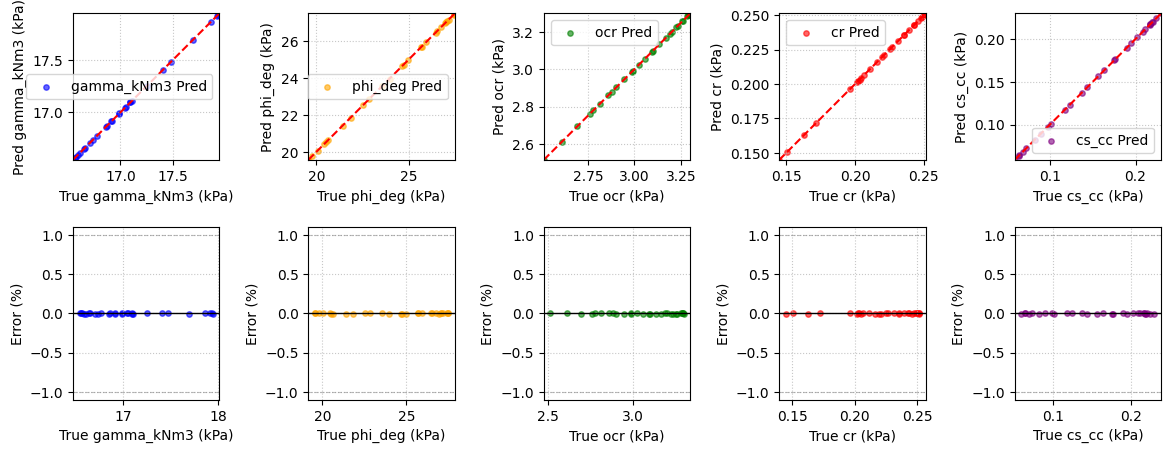

In [45]:
# --- 1. (Self-Correction/Update) Ensure fs error is on the physical scale ---
# If test["fs_pred"] is log-space, we calculate the pct error using the exponentiated values

# Create a 2x5 grid (2 rows, 5 columns)
fig, axes = plt.subplots(2, 5, figsize=(5*6*cm, 12*cm))

# Row 0: Prediction vs True
# Row 1: Residuals vs True

variables = [
    {"name": "gamma_kNm3", "true": "gamma_kNm3", "pred": "gamma_kNm3_pred", "err": "gamma_kNm3_error_pct", "color": "blue"},
    {"name": "phi_deg", "true": "phi_deg", "pred": "phi_deg_pred", "err": "phi_deg_error_pct", "color": "orange"},
    {"name": "ocr", "true": "ocr", "pred": "ocr_pred", "err": "ocr_error_pct", "color": "green"},
    {"name": "cr", "true": "cr", "pred": "cr_pred", "err": "cr_error_pct", "color": "red"},
    {"name": "cs_cc", "true": "cs_cc", "pred": "cs_cc_pred", "err": "cs_cc_error_pct", "color": "purple"}
]

for i, var in enumerate(variables):
    # --- Top Row: Predicted vs True ---
    ax_top = axes[0, i]
    
    # Extract data (handling the exp transformation for fs)
    x_val = test[var["true"]]
    y_val = np.exp(test[var["pred"]]) if var["name"] == "fs" else test[var["pred"]]
    
    ax_top.scatter(x_val, y_val, label=f"{var['name']} Pred", color=var["color"], s=15, alpha=0.6)
    
    # 45-degree line logic
    mn = min(x_val.min(), y_val.min())
    mx = max(x_val.max(), y_val.max())
    ax_top.plot([mn, mx], [mn, mx], color='red', linestyle='--', lw=1.5)
    
    ax_top.set_xlim([mn, mx]), ax_top.set_ylim([mn, mx])
    ax_top.set_aspect('equal')
    ax_top.set_xlabel(f"True {var['name']} (kPa)")
    ax_top.set_ylabel(f"Pred {var['name']} (kPa)")
    ax_top.legend()
    ax_top.grid(True, linestyle=':', alpha=0.7)

    # --- Bottom Row: Residuals ---
    ax_bot = axes[1, i]
    err_val = test[var["err"]]
    
    ax_bot.scatter(x_val, err_val, color=var["color"], s=15, alpha=0.6)
    
    # Add zero-error baseline
    ax_bot.axhline(0, color='black', linestyle='-', lw=1)
    
    # Add +/- 10% or 20% bounds for reference
    ax_bot.axhline(1, color='gray', linestyle='--', lw=0.8, alpha=0.5)
    ax_bot.axhline(-1, color='gray', linestyle='--', lw=0.8, alpha=0.5)
    
    ax_bot.set_xlabel(f"True {var['name']} (kPa)")
    ax_bot.set_ylabel("Error (%)")
    ax_bot.grid(True, linestyle=':', alpha=0.7)
    
    # Optional: limit Y-axis if there are extreme outliers to keep plot readable
    # ax_bot.set_ylim([-50, 50]) 

plt.tight_layout()

In [46]:
# Close UQ[PY]LAB session
mySession.quit()
print("UQ[PY]LAB session closed.")

 uqpylab.sessions :: INFO     :: Session 682498b277f74e7fb20999e0b249fe1a terminated.
UQ[PY]LAB session closed.
